In [1]:
from pathlib import Path
import sys
import math

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

PROJECT_DIR = Path.cwd()
if not (PROJECT_DIR / "src" / "distance_measures.py").exists():
    raise FileNotFoundError(
        "Open this notebook from the Credit_Card_Distance_Analysis project folder. "
        "The 'src/distance_measures.py' file should be inside that folder."
    )

DATA_DIR = PROJECT_DIR / "data"
OUTPUT_DIR = PROJECT_DIR / "outputs"
CSV_PATH = DATA_DIR / "creditcard.csv"
OUTPUT_DIR.mkdir(exist_ok=True)
sys.path.insert(0, str(PROJECT_DIR / "src"))

from distance_measures import (
    euclidean_distance,
    manhattan_distance,
    cosine_distance,
    pairwise_distance_matrix,
)

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
print("Project folder:", PROJECT_DIR)
print("Dataset path:", CSV_PATH)

Project folder: C:\Users\Saeed.kh\Desktop\HW-2
Dataset path: C:\Users\Saeed.kh\Desktop\HW-2\data\creditcard.csv


In [2]:
point_a = [1, 2]
point_b = [4, 6]

print("Euclidean:", round(euclidean_distance(point_a, point_b), 4))
print("Manhattan:", round(manhattan_distance(point_a, point_b), 4))
print("Cosine distance:", round(cosine_distance(point_a, point_b), 4))

Euclidean: 5.0
Manhattan: 7.0
Cosine distance: 0.0077


In [3]:
if not CSV_PATH.exists():
    raise FileNotFoundError(
        "creditcard.csv was not found. Download it from Kaggle and place it at: "
        f"{CSV_PATH}"
    )

df = pd.read_csv(CSV_PATH)

required_columns = {"Class", "Time", "Amount", "V1", "V2"}
missing_columns = required_columns.difference(df.columns)
if missing_columns:
    raise ValueError(f"The CSV is missing required columns: {sorted(missing_columns)}")

df["Class"] = pd.to_numeric(df["Class"], errors="raise").astype(int)
if not set(df["Class"].unique()).issubset({0, 1}):
    raise ValueError("Class should contain only 0 (legitimate) and 1 (fraudulent).")

df["Source_Row"] = np.arange(len(df))
df["Class_Label"] = df["Class"].map({0: "Legitimate", 1: "Fraudulent"})

excluded_columns = {"Class", "Class_Label", "Source_Row", "Transaction_ID"}
feature_cols = [
    column for column in df.columns
    if column not in excluded_columns and pd.api.types.is_numeric_dtype(df[column])
]

if len(feature_cols) < 3:
    raise ValueError("The assignment requires at least three numeric features.")

class_counts = df["Class_Label"].value_counts().reindex(["Legitimate", "Fraudulent"])
fraud_rate = 100 * class_counts["Fraudulent"] / len(df)

print(f"Dataset shape: {df.shape[0]:,} rows × {df.shape[1]:,} columns")
print(f"Numeric features used for distances: {len(feature_cols)}")
print("Class counts:")
display(class_counts.to_frame("Transactions"))
print(f"Fraud prevalence: {fraud_rate:.4f}%")
print("Missing values in numeric features:", int(df[feature_cols].isna().sum().sum()))

summary = pd.DataFrame({
    "Metric": ["Rows", "Numeric features", "Legitimate transactions", "Fraudulent transactions", "Fraud prevalence (%)"],
    "Value": [len(df), len(feature_cols), int(class_counts["Legitimate"]), int(class_counts["Fraudulent"]), fraud_rate],
})
summary.to_csv(OUTPUT_DIR / "dataset_summary.csv", index=False)

Dataset shape: 284,807 rows × 33 columns
Numeric features used for distances: 30
Class counts:


,Transactions
Class_Label,
Legitimate,284315
Fraudulent,492


Fraud prevalence: 0.1727%
Missing values in numeric features: 0


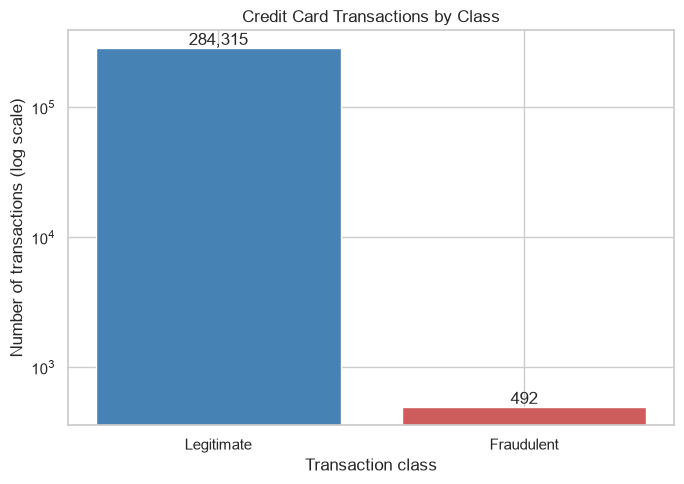

Interpretation: the logarithmic axis makes both classes visible. The fraudulent class is much smaller than the legitimate class, so the original dataset is highly imbalanced.


In [4]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.bar(class_counts.index, class_counts.values, color=["steelblue", "indianred"])
ax.set_yscale("log")
ax.set_title("Credit Card Transactions by Class")
ax.set_xlabel("Transaction class")
ax.set_ylabel("Number of transactions (log scale)")
for position, value in enumerate(class_counts.values):
    ax.text(position, value, f"{value:,}", ha="center", va="bottom")
plt.tight_layout()
fig.savefig(OUTPUT_DIR / "class_distribution.png", dpi=160, bbox_inches="tight")
plt.show()

print("Interpretation: the logarithmic axis makes both classes visible. The fraudulent class is much smaller than the legitimate class, so the original dataset is highly imbalanced.")

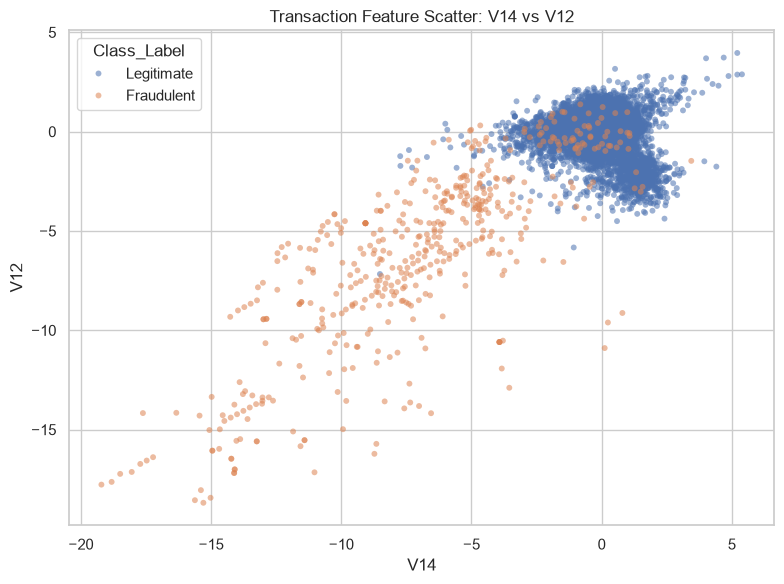

Interpretation: look for overlap or separation between the two colours. The plot includes every fraud case and a random sample of up to 12,000 legitimate cases so the minority class is easier to inspect; it is not a prevalence-preserving sample.


In [5]:
x_feature = "V14" if "V14" in df.columns else "V1"
y_feature = "V12" if "V12" in df.columns else "V2"

legitimate_plot = df.loc[df["Class"] == 0].sample(
    n=min(12000, int((df["Class"] == 0).sum())), random_state=RANDOM_STATE
)
fraudulent_plot = df.loc[df["Class"] == 1]
scatter_data = pd.concat([legitimate_plot, fraudulent_plot], ignore_index=True)

fig, ax = plt.subplots(figsize=(8, 6))
sns.scatterplot(
    data=scatter_data,
    x=x_feature,
    y=y_feature,
    hue="Class_Label",
    hue_order=["Legitimate", "Fraudulent"],
    alpha=0.55,
    s=18,
    linewidth=0,
    ax=ax,
)
ax.set_title(f"Transaction Feature Scatter: {x_feature} vs {y_feature}")
ax.set_xlabel(x_feature)
ax.set_ylabel(y_feature)
plt.tight_layout()
fig.savefig(OUTPUT_DIR / "feature_scatter.png", dpi=160, bbox_inches="tight")
plt.show()

print("Interpretation: look for overlap or separation between the two colours. The plot includes every fraud case and a random sample of up to 12,000 legitimate cases so the minority class is easier to inspect; it is not a prevalence-preserving sample.")

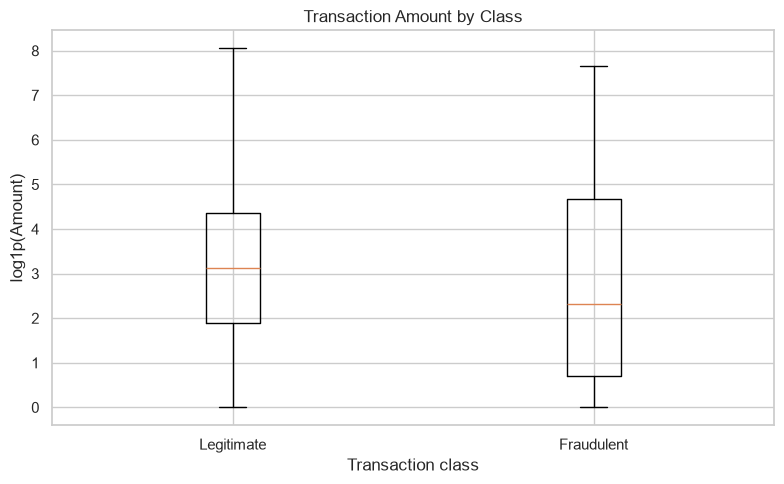

Interpretation: compare the median lines and interquartile ranges. A difference suggests that transaction amounts have different distributions across classes. The log transform makes the central distributions easier to compare; fliers are hidden in this boxplot to keep it readable.


In [6]:
amount_log = np.log1p(df["Amount"].clip(lower=0))

amount_groups = [
    amount_log[df["Class"] == 0].dropna(),
    amount_log[df["Class"] == 1].dropna(),
]

fig, ax = plt.subplots(figsize=(8, 5))
ax.boxplot(
    amount_groups,
    tick_labels=["Legitimate", "Fraudulent"],
    showfliers=False
)

ax.set_title("Transaction Amount by Class")
ax.set_ylabel("log1p(Amount)")
ax.set_xlabel("Transaction class")

plt.tight_layout()
fig.savefig(OUTPUT_DIR / "amount_boxplot.png", dpi=160, bbox_inches="tight")
plt.show()

print(
    "Interpretation: compare the median lines and interquartile ranges. "
    "A difference suggests that transaction amounts have different "
    "distributions across classes. The log transform makes the central "
    "distributions easier to compare; fliers are hidden in this boxplot "
    "to keep it readable."
)

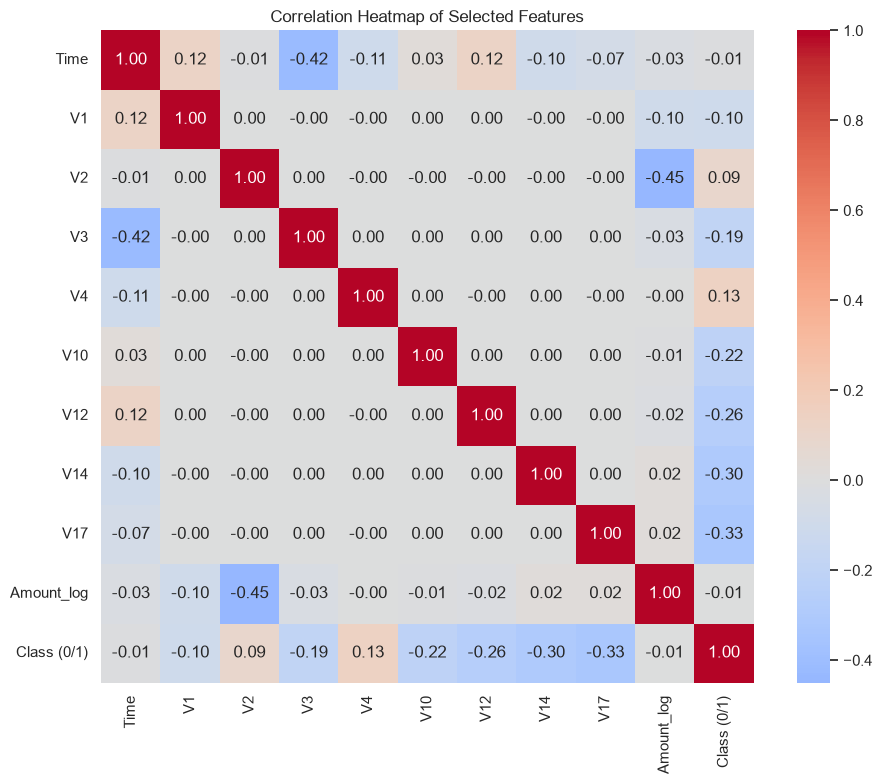

Interpretation: values near +1 indicate positive linear association; values near -1 indicate negative association; values near 0 indicate weak linear association. The Class column is included here only as an encoded label for exploratory correlation; it is excluded from distance calculations.


In [7]:
selected_features = [
    column for column in ["Time", "V1", "V2", "V3", "V4", "V10", "V12", "V14", "V17"]
    if column in df.columns
]
correlation_data = df[selected_features].copy()
correlation_data["Amount_log"] = np.log1p(df["Amount"].clip(lower=0))
correlation_data["Class (0/1)"] = df["Class"]
correlation_matrix = correlation_data.corr()

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(correlation_matrix, cmap="coolwarm", center=0, annot=True, fmt=".2f", square=True, ax=ax)
ax.set_title("Correlation Heatmap of Selected Features")
plt.tight_layout()
fig.savefig(OUTPUT_DIR / "feature_correlation_heatmap.png", dpi=160, bbox_inches="tight")
plt.show()

print("Interpretation: values near +1 indicate positive linear association; values near -1 indicate negative association; values near 0 indicate weak linear association. The Class column is included here only as an encoded label for exploratory correlation; it is excluded from distance calculations.")

In [8]:
SAMPLE_PER_CLASS = 100

legitimate_sample = df.loc[df["Class"] == 0].sample(
    n=min(SAMPLE_PER_CLASS, int((df["Class"] == 0).sum())),
    random_state=RANDOM_STATE,
)
fraudulent_sample = df.loc[df["Class"] == 1].sample(
    n=min(SAMPLE_PER_CLASS, int((df["Class"] == 1).sum())),
    random_state=RANDOM_STATE,
)

distance_sample = pd.concat([legitimate_sample, fraudulent_sample]).copy()
source_indices = distance_sample.index.copy()
distance_sample = distance_sample.reset_index(drop=True)

features_for_distance = df[feature_cols].copy()
if "Amount" in features_for_distance.columns:
    features_for_distance["Amount"] = np.log1p(features_for_distance["Amount"].clip(lower=0))

features_for_distance = features_for_distance.fillna(features_for_distance.median())
feature_means = features_for_distance.mean()
feature_stds = features_for_distance.std(ddof=0).replace(0, 1)
scaled_features = (features_for_distance - feature_means) / feature_stds

X_sample = scaled_features.loc[source_indices].reset_index(drop=True)
X = X_sample.to_numpy(dtype=float)

if not np.isfinite(X).all():
    raise ValueError("The prepared feature matrix contains NaN or infinite values.")

n_legitimate = int((distance_sample["Class"] == 0).sum())
n_fraudulent = int((distance_sample["Class"] == 1).sum())
print("Distance-analysis sample:", len(distance_sample), "transactions")
print("Legitimate:", n_legitimate, "| Fraudulent:", n_fraudulent)
print("Feature matrix shape:", X.shape)
display(distance_sample[["Source_Row", "Class_Label"]].head())

distance_sample[["Source_Row", "Class", "Class_Label"]].to_csv(
    OUTPUT_DIR / "distance_sample_transactions.csv", index=False
)

Distance-analysis sample: 200 transactions
Legitimate: 100 | Fraudulent: 100
Feature matrix shape: (200, 30)


,Source_Row,Class_Label
0,138028,Legitimate
1,63099,Legitimate
2,73411,Legitimate
3,164247,Legitimate
4,148999,Legitimate


In [9]:
metric_names = ["euclidean", "manhattan", "cosine"]
distance_matrices = {}

for metric in metric_names:
    distance_matrices[metric] = np.array(
        pairwise_distance_matrix(X, metric=metric), dtype=float
    )

transaction_ids = distance_sample["Source_Row"].astype(str).tolist()
for metric, matrix in distance_matrices.items():
    matrix_df = pd.DataFrame(matrix, index=transaction_ids, columns=transaction_ids)
    matrix_df.index.name = "Source_Row"
    matrix_df.to_csv(OUTPUT_DIR / f"{metric}_distance_matrix.csv")

print("Created distance matrices:")
for metric, matrix in distance_matrices.items():
    print(f"{metric.title():<12} {matrix.shape}")

Created distance matrices:
Euclidean    (200, 200)
Manhattan    (200, 200)
Cosine       (200, 200)


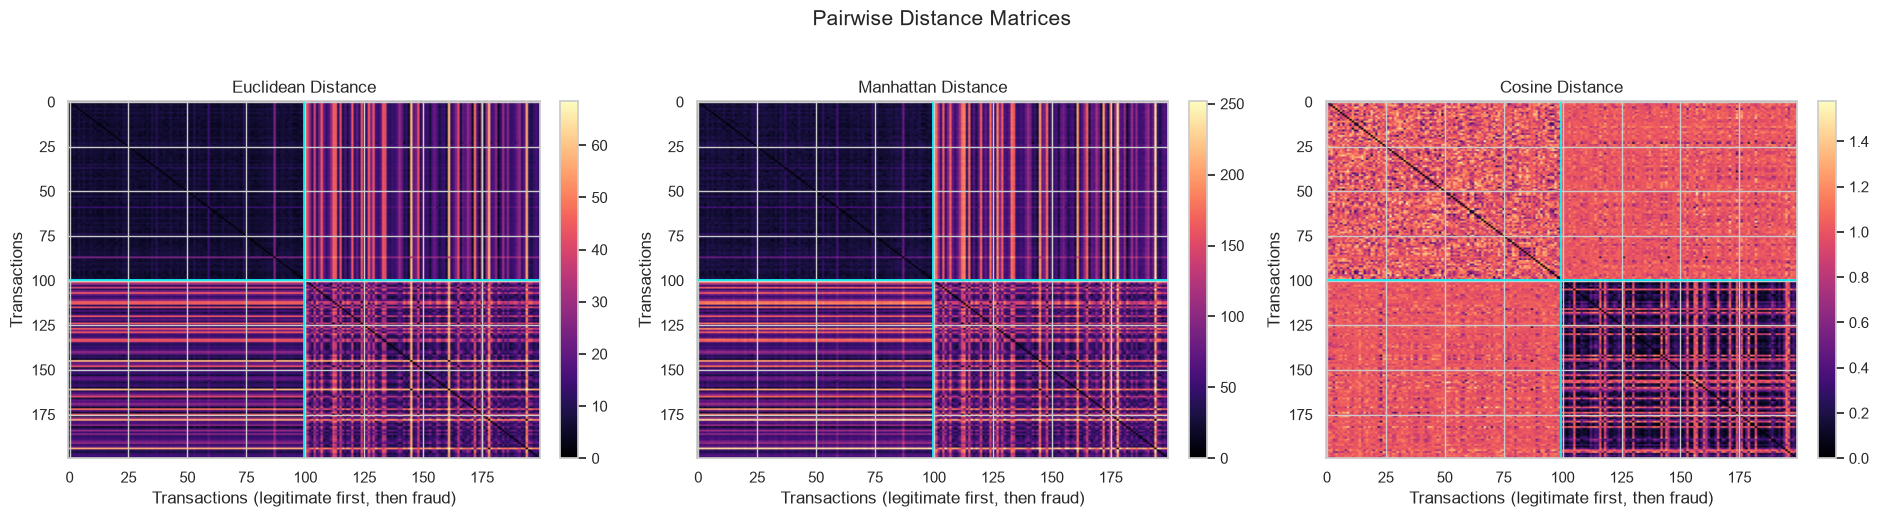

Interpretation: brighter cells represent larger distances for that specific metric. The horizontal and vertical boundary separates legitimate transactions from fraudulent transactions. Compare the within-class blocks with the between-class blocks; the colour scales differ between metrics, so compare patterns within each panel rather than raw colours across panels.


In [10]:
fig, axes = plt.subplots(1, 3, figsize=(19, 5))

for ax, metric in zip(axes, metric_names):
    matrix = distance_matrices[metric]
    image = ax.imshow(matrix, cmap="magma", aspect="auto")
    ax.axhline(n_legitimate - 0.5, color="cyan", linewidth=1.2)
    ax.axvline(n_legitimate - 0.5, color="cyan", linewidth=1.2)
    ax.set_title(f"{metric.title()} Distance")
    ax.set_xlabel("Transactions (legitimate first, then fraud)")
    ax.set_ylabel("Transactions")
    fig.colorbar(image, ax=ax, fraction=0.046, pad=0.04)

fig.suptitle("Pairwise Distance Matrices", y=1.03, fontsize=15)
plt.tight_layout()
fig.savefig(OUTPUT_DIR / "distance_heatmaps.png", dpi=160, bbox_inches="tight")
plt.show()

print("Interpretation: brighter cells represent larger distances for that specific metric. The horizontal and vertical boundary separates legitimate transactions from fraudulent transactions. Compare the within-class blocks with the between-class blocks; the colour scales differ between metrics, so compare patterns within each panel rather than raw colours across panels.")

In [11]:
pair_labels = distance_sample["Class"].to_numpy()
pair_groups = ["Legitimate-Legitimate", "Fraudulent-Fraudulent", "Legitimate-Fraudulent"]
all_summary_rows = []
all_pair_values = {}

for metric in metric_names:
    matrix = distance_matrices[metric]
    grouped_values = {group: [] for group in pair_groups}

    for i in range(len(pair_labels)):
        for j in range(i + 1, len(pair_labels)):
            class_i = pair_labels[i]
            class_j = pair_labels[j]

            if class_i == 0 and class_j == 0:
                group = "Legitimate-Legitimate"
            elif class_i == 1 and class_j == 1:
                group = "Fraudulent-Fraudulent"
            else:
                group = "Legitimate-Fraudulent"

            grouped_values[group].append(float(matrix[i, j]))

    all_pair_values[metric] = grouped_values

    for group, values in grouped_values.items():
        all_summary_rows.append({
            "Metric": metric.title(),
            "Pair_Group": group,
            "Pair_Count": len(values),
            "Mean_Distance": float(np.mean(values)),
            "Median_Distance": float(np.median(values)),
            "Std_Distance": float(np.std(values)),
            "Min_Distance": float(np.min(values)),
            "Max_Distance": float(np.max(values)),
        })

distance_summary = pd.DataFrame(all_summary_rows)
distance_summary.to_csv(OUTPUT_DIR / "distance_group_summary.csv", index=False)
display(distance_summary.round(4))

,Metric,Pair_Group,Pair_Count,Mean_Distance,Median_Distance,Std_Distance,Min_Distance,Max_Distance
0,Euclidean,Legitimate-Legitimate,4950,7.0283,6.5555,2.9196,1.4594,25.8316
1,Euclidean,Fraudulent-Fraudulent,4950,23.3565,18.4165,13.8498,0.0000,68.4897
2,Euclidean,Legitimate-Fraudulent,10000,22.0734,16.8138,13.6555,2.8689,61.8033
3,Manhattan,Legitimate-Legitimate,4950,29.0608,27.5039,9.9265,5.1639,88.8572
4,Manhattan,Fraudulent-Fraudulent,4950,90.7505,73.4562,50.6576,0.0000,242.6501
5,Manhattan,Legitimate-Fraudulent,10000,87.9150,68.5779,53.3098,12.6639,251.8716
6,Cosine,Legitimate-Legitimate,4950,0.9970,1.0215,0.2171,0.0418,1.5785
7,Cosine,Fraudulent-Fraudulent,4950,0.4908,0.3607,0.3597,0.0000,1.3842
8,Cosine,Legitimate-Fraudulent,10000,1.0015,1.0104,0.1127,0.1017,1.5387


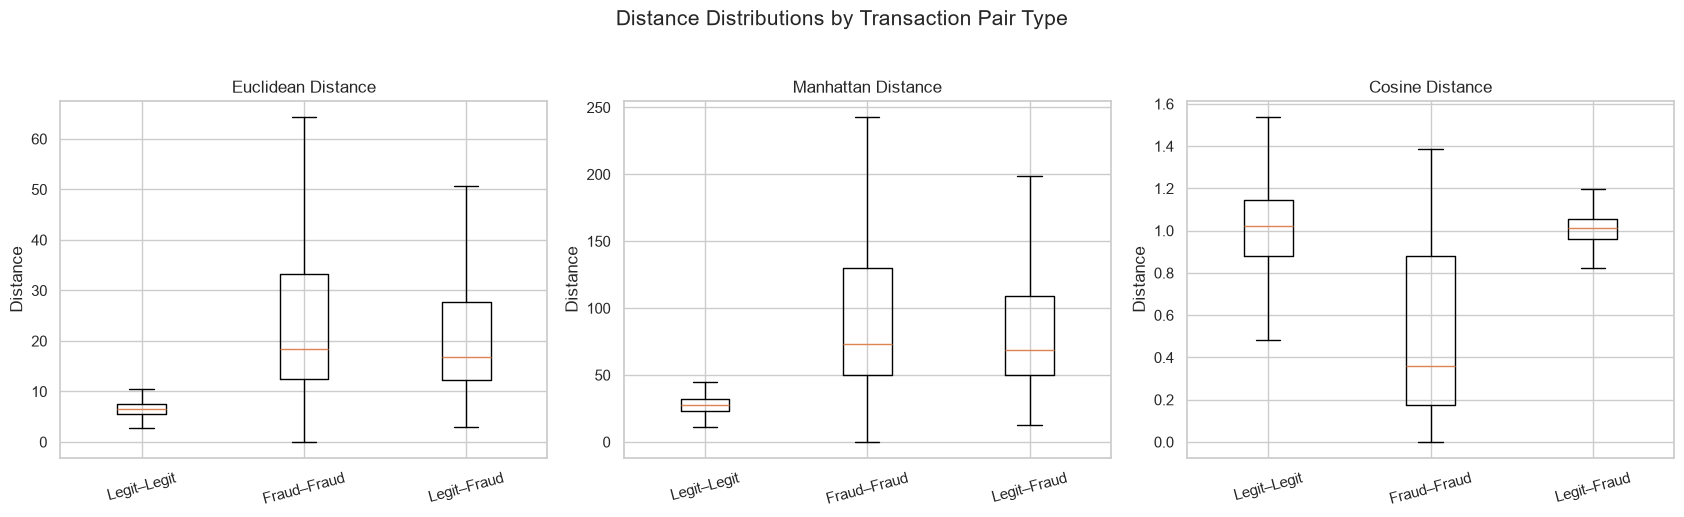

Interpretation: compare the medians and spread of the three pair groups in each panel. A higher Legit–Fraud distribution suggests greater separation between classes under that measure. Overlapping boxes and whiskers indicate that many cross-class pairs have distances similar to within-class pairs.


In [12]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
short_labels = ["Legit–Legit", "Fraud–Fraud", "Legit–Fraud"]

for ax, metric in zip(axes, metric_names):
    values = [all_pair_values[metric][group] for group in pair_groups]

    ax.boxplot(
        values,
        tick_labels=short_labels,
        showfliers=False
    )

    ax.set_title(f"{metric.title()} Distance")
    ax.set_ylabel("Distance")
    ax.tick_params(axis="x", rotation=15)

fig.suptitle("Distance Distributions by Transaction Pair Type", y=1.03, fontsize=15)
plt.tight_layout()
fig.savefig(OUTPUT_DIR / "distance_group_boxplots.png", dpi=160, bbox_inches="tight")
plt.show()

print(
    "Interpretation: compare the medians and spread of the three pair groups "
    "in each panel. A higher Legit–Fraud distribution suggests greater "
    "separation between classes under that measure. Overlapping boxes and "
    "whiskers indicate that many cross-class pairs have distances similar "
    "to within-class pairs."
)

In [13]:
for metric in metric_names:
    metric_rows = distance_summary[distance_summary["Metric"] == metric.title()].set_index("Pair_Group")
    same_class_count = (
        metric_rows.loc["Legitimate-Legitimate", "Pair_Count"]
        + metric_rows.loc["Fraudulent-Fraudulent", "Pair_Count"]
    )
    same_class_total = (
        metric_rows.loc["Legitimate-Legitimate", "Mean_Distance"]
        * metric_rows.loc["Legitimate-Legitimate", "Pair_Count"]
        + metric_rows.loc["Fraudulent-Fraudulent", "Mean_Distance"]
        * metric_rows.loc["Fraudulent-Fraudulent", "Pair_Count"]
    )
    within_mean = same_class_total / same_class_count
    between_mean = metric_rows.loc["Legitimate-Fraudulent", "Mean_Distance"]

    relation = "greater than" if between_mean > within_mean else "not greater than"
    print(
        f"{metric.title()}: mean between-class distance ({between_mean:.4f}) is {relation} "
        f"the weighted mean within-class distance ({within_mean:.4f})."
    )

print("\nRemember: these comparisons describe the selected balanced sample and the chosen standardized feature space. They do not establish that a transaction is fraudulent.")

Euclidean: mean between-class distance (22.0734) is greater than the weighted mean within-class distance (15.1924).
Manhattan: mean between-class distance (87.9150) is greater than the weighted mean within-class distance (59.9056).
Cosine: mean between-class distance (1.0015) is greater than the weighted mean within-class distance (0.7439).

Remember: these comparisons describe the selected balanced sample and the chosen standardized feature space. They do not establish that a transaction is fraudulent.
